# Hostinger product analytics: analysis notebook

Independent case study for Hostinger's Product Data Analyst role. **SIMULATED data** (seed 42): product events are generated by
`src/generate_product_sim.py` for the **same simulated customers** as the marketing part (same ids, countries, devices, order dates and
acquisition channels). Public facts used (Reach plans, referral terms) are listed in `data/SOURCES.md`. Not Hostinger data, not affiliated with Hostinger.

SQL (`sql/08` to `sql/11`) builds the funnel, retention, test and referral tables. This notebook does the statistics:

1. **A/B test** on Reach onboarding: plan written before the test, power, sample-ratio check, z-test and bootstrap, segments, decision
2. **Aha moment**: is "first campaign within 7 days" a good definition of adoption? Correlation, not causation, and the test that would prove it
3. **Mail AI replies**: which segments really use the mailbox more after the rollout (difference-in-differences)
4. **Referral programme**: profitability by reward level and a "what if we change the reward" scenario

Run `python src/generate_sim.py`, `python src/generate_product_sim.py` and `python src/run_sql.py` first.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "data" / "output"
CLEAN = ROOT / "data" / "clean"
rng = np.random.default_rng(42)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
BLUE, GREY, INK, RED = "#2A78D6", "#B4B2A9", "#0B0B0B", "#D03B3B"

## 1 · A/B test: AI-prefilled first campaign vs blank editor

### 1.1 Test plan (written before the test started)

| | |
|---|---|
| **Hypothesis** | A first campaign pre-filled by AI (copy, layout, subject line) removes the blank-page problem, so more new Reach users send a first campaign quickly. |
| **Unit and split** | user, at onboarding start, 50 / 50, from 4 May 2026 |
| **Primary metric** | share of users who send a first campaign **within 7 days** of the start (the aha moment, section 2) |
| **Guardrails** | day-30 retention and upgrade to a paid plan within 60 days must not drop |
| **Duration** | 16 weeks, fixed by the product calendar (4 May - 23 Aug 2026) |
| **Minimum detectable effect** | what 16 weeks of traffic can detect at 80% power (computed below); the team's bar is +2.5 points (about +10% relative): below that, the AI cost is not worth it |
| **Risk levels** | α = 5% two-sided, power 80% |
| **Sample-ratio check** | chi-square on users per variant; p < 0.001 = stop and investigate before reading any effect |
| **Reading** | once, at the planned end. No peeking: looking every day and stopping at the first p < 0.05 inflates false positives |
| **Segments** | platform, onboarding source, country group: exploratory only, Holm correction |

In [2]:
# Baseline: 7-day activation of users who started onboarding in the 4 months before the test
users = pd.read_csv(OUT / "reach_users.csv", parse_dates=["started_ts", "onboarding_date"])
pre = users[(users.started_ts >= "2026-01-01") & (users.started_ts < "2026-05-01") & users.funnel_complete]
p0 = pre.activated_7d.mean()
weekly_starts = len(pre) / (pre.started_ts.max() - pre.started_ts.min()).days * 7

def n_per_arm(p0, mde, alpha=.05, power=.80):
    # sample size per arm to detect p0 -> p0 + mde with a two-sided two-proportion z-test
    p1 = p0 + mde
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return int(np.ceil(z ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / mde ** 2))

N_AVAILABLE = int(16 * weekly_starts / 2)                       # users per arm in 16 weeks
MDE = next(m / 1000 for m in range(5, 100) if n_per_arm(p0, m / 1000) <= N_AVAILABLE)   # smallest effect detectable
N_PLAN = n_per_arm(p0, MDE)
print(f"baseline 7-day activation {p0:.1%}; {weekly_starts:,.0f} onboarding starts a week -> {N_AVAILABLE:,} users per arm in 16 weeks")
print(f"minimum detectable effect at 80% power: +{MDE * 100:.1f} pts ({N_PLAN:,} users per arm needed)")
print(f"the +2.5 pt bar would need {n_per_arm(p0, .025):,} users per arm ({2 * n_per_arm(p0, .025) / weekly_starts:.1f} weeks):"
      " a true +2.5 pt effect has a bit less than 80% power in 16 weeks")

power_curve = pd.DataFrame({"mde_points": np.round(np.arange(1.0, 5.01, .25), 2)})
power_curve["users_per_arm"] = [n_per_arm(p0, m / 100) for m in power_curve.mde_points]
power_curve["weeks_needed"] = 2 * power_curve.users_per_arm / weekly_starts
power_curve.to_csv(OUT / "ab_power.csv", index=False)
power_curve.iloc[::4]

baseline 7-day activation 23.7%; 509 onboarding starts a week -> 4,074 users per arm in 16 weeks
minimum detectable effect at 80% power: +2.7 pts (4,042 users per arm needed)
the +2.5 pt bar would need 4,702 users per arm (18.5 weeks): a true +2.5 pt effect has a bit less than 80% power in 16 weeks


,mde_points,users_per_arm,weeks_needed
0,1.0,28809,113.119991
4,2.0,7300,28.663818
8,3.0,3286,12.902645
12,4.0,1871,7.346576
16,5.0,1211,4.755053


### 1.2 Sample-ratio mismatch (SRM) check, before looking at any result

With a 50/50 split, the number of users per variant should differ only by chance. A chi-square goodness-of-fit test against 50/50
tells how unlikely the observed split is. An SRM means the groups are no longer comparable (a bug in assignment or logging),
so the effect cannot be trusted until the cause is found.

In [3]:
ab = pd.read_csv(OUT / "ab_users.csv", parse_dates=["assigned_ts", "assigned_date"])
daily = pd.read_csv(OUT / "ab_daily.csv", parse_dates=["assigned_date"])

def srm(df):
    counts = df.variant.value_counts().reindex(["control", "treatment"]).values
    chi2, p = stats.chisquare(counts)            # expected: equal split
    return counts, chi2, p

counts, chi2, p_srm = srm(ab)
print(f"all users: control {counts[0]:,} vs treatment {counts[1]:,}; chi-square {chi2:.1f}, p = {p_srm:.1e}  -> SRM")

# where does it come from? daily z-score of the treatment count (computed in sql/10_ab_test.sql)
bad = daily[daily.srm_z.abs() > 3]
print(bad[["assigned_date", "users", "control_users", "treatment_users", "control_mobile", "treatment_mobile", "srm_z"]])

all users: control 5,288 vs treatment 4,564; chi-square 53.2, p = 3.0e-13  -> SRM
   assigned_date  users  control_users  treatment_users  control_mobile  treatment_mobile      srm_z
71    2026-07-14   1185            934              251             648                 0 -19.840907


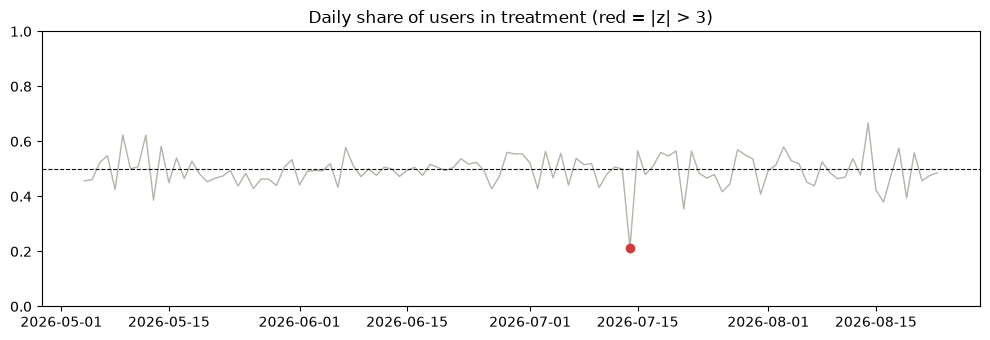

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.assigned_date, daily.treatment_share, color=GREY, lw=1)
ax.scatter(bad.assigned_date, bad.treatment_share, color=RED, zorder=3)
ax.axhline(.5, color=INK, ls="--", lw=.8)
ax.set_title("Daily share of users in treatment (red = |z| > 3)"); ax.set_ylim(0, 1)
plt.tight_layout();

**Diagnosis.** On 14 July (the day Reach was in the customer newsletter, ~1,200 starts), **every mobile user went to control**,
while desktop users were split normally: a release bug in the assignment service on mobile. Those users were not randomised.
The newsletter users also activate less than average, so keeping that day would put weaker users in control only and
**inflate the effect**. Decision: remove every user assigned on 14 July (both variants) and re-check.

In [5]:
BUG_DAY = pd.Timestamp("2026-07-14")
clean = ab[ab.assigned_date != BUG_DAY].copy()
counts_c, chi2_c, p_srm_c = srm(clean)
print(f"without 14 July: control {counts_c[0]:,} vs treatment {counts_c[1]:,}; chi-square {chi2_c:.2f}, p = {p_srm_c:.2f}  -> no SRM")
mob = clean.groupby("variant").platform.apply(lambda s: (s == "Web - mobile").mean())
print("mobile share by variant:", mob.round(3).to_dict())
pd.DataFrame([("All assigned users", *counts, chi2, p_srm), ("Without 14 July", *counts_c, chi2_c, p_srm_c)],
             columns=["sample", "control_users", "treatment_users", "chi_square", "p_value"]).to_csv(OUT / "ab_srm.csv", index=False)

without 14 July: control 4,354 vs treatment 4,313; chi-square 0.19, p = 0.66  -> no SRM
mobile share by variant: {'control': 0.542, 'treatment': 0.549}


### 1.3 Effect on the primary metric: z-test and bootstrap

In [6]:
def two_prop(df, metric):
    # difference treatment - control, pooled two-proportion z-test, 95% CI (unpooled standard error)
    g = df.groupby("variant")[metric].agg(["mean", "count", "sum"])
    pc, pt = g.loc["control", "mean"], g.loc["treatment", "mean"]
    nc, nt = g.loc["control", "count"], g.loc["treatment", "count"]
    pool = (g["sum"].sum()) / (nc + nt)
    z = (pt - pc) / np.sqrt(pool * (1 - pool) * (1 / nc + 1 / nt))
    se = np.sqrt(pc * (1 - pc) / nc + pt * (1 - pt) / nt)
    return dict(control=pc, treatment=pt, diff=pt - pc, ci_low=pt - pc - 1.96 * se, ci_high=pt - pc + 1.96 * se,
                p_value=2 * stats.norm.sf(abs(z)), n_control=nc, n_treatment=nt)

def bootstrap_diff(df, metric, n=5000):
    # resample users with replacement inside each variant
    c = df.loc[df.variant == "control", metric].values.astype(float)
    t = df.loc[df.variant == "treatment", metric].values.astype(float)
    diffs = np.concatenate([rng.choice(t, (500, len(t))).mean(axis=1) - rng.choice(c, (500, len(c))).mean(axis=1)
                            for _ in range(n // 500)])           # 500 resamples at a time to save memory
    return np.percentile(diffs, [2.5, 97.5])

primary = two_prop(clean, "activated_7d")
boot = bootstrap_diff(clean, "activated_7d")
biased = two_prop(ab, "activated_7d")
print(f"7-day activation: control {primary['control']:.1%} vs treatment {primary['treatment']:.1%}")
print(f"effect {primary['diff'] * 100:+.1f} pts ({primary['diff'] / primary['control']:+.0%} relative), "
      f"95% CI {primary['ci_low'] * 100:+.1f} to {primary['ci_high'] * 100:+.1f} pts, p = {primary['p_value']:.3f}")
print(f"bootstrap 95% CI: {boot[0] * 100:+.1f} to {boot[1] * 100:+.1f} pts")
print(f"with the bad day kept, the effect would read {biased['diff'] * 100:+.1f} pts: the SRM inflated it")

7-day activation: control 25.3% vs treatment 27.8%
effect +2.5 pts (+10% relative), 95% CI +0.7 to +4.4 pts, p = 0.008
bootstrap 95% CI: +0.6 to +4.4 pts
with the bad day kept, the effect would read +3.3 pts: the SRM inflated it


### 1.4 Guardrails and funnel steps

In [7]:
rows = []
for metric, label, sample in (("activated_7d", "First campaign within 7 days (primary)", clean),
                              ("reached_template", "Template chosen", clean),
                              ("reached_contacts", "Contacts imported", clean),
                              ("retained_d30", "Day-30 retention (guardrail)", clean[clean.mature_d30]),
                              ("upgraded_60d", "Upgrade within 60 days (guardrail)", clean[clean.mature_60d])):
    r = two_prop(sample, metric)
    lo, hi = bootstrap_diff(sample, metric, 2000) if metric != "activated_7d" else boot
    rows.append(dict(metric=label, **r, boot_ci_low=lo, boot_ci_high=hi))
ab_result = pd.DataFrame(rows)
ab_result["relative_lift"] = ab_result["diff"] / ab_result["control"]
# Holm correction across the 4 secondary metrics (the primary metric is tested alone)
sec = ab_result.index[1:]
order = ab_result.loc[sec, "p_value"].argsort().values
adj = np.maximum.accumulate((len(sec) - np.arange(len(sec))) * ab_result.loc[sec, "p_value"].values[order]).clip(max=1)
ab_result.loc[sec[order], "p_holm"] = adj
ab_result.loc[0, "p_holm"] = ab_result.loc[0, "p_value"]
ab_result["rank"] = range(1, len(ab_result) + 1)
ab_result.to_csv(OUT / "ab_result.csv", index=False)
ab_result[["metric", "control", "treatment", "diff", "ci_low", "ci_high", "p_value", "p_holm"]].round(4)

,metric,control,treatment,diff,ci_low,ci_high,p_value,p_holm
0,First campaign within 7 days (primary),0.2533,0.2785,0.0251,0.0065,0.0437,0.0081,0.0081
1,Template chosen,0.8319,0.8604,0.0285,0.0134,0.0437,0.0002,0.0009
2,Contacts imported,0.4924,0.4941,0.0017,-0.0194,0.0227,0.8767,1.0000
3,Day-30 retention (guardrail),0.3018,0.3016,-0.0001,-0.0195,0.0192,0.9882,1.0000
4,Upgrade within 60 days (guardrail),0.1054,0.0923,-0.0131,-0.0257,-0.0006,0.0404,0.1213


### 1.5 Segments (exploratory, with caution)

Every extra segment is another test: with 8 comparisons, one "significant" result is likely by chance alone.
The Holm correction adjusts the p-values for that. The right question is not "is the effect significant in this segment?"
but "is the effect **different** between segments?": an interaction test compares the two effects directly. Segment effects are read only to generate ideas for the next test,
never to ship to one segment after the fact. "Test half" checks for a **novelty effect** (an effect that fades once users get used to the feature).

In [8]:
clean["country_group"] = np.where(clean.country.isin(["US", "FR", "ES"]), "US, FR, ES", "BR, IN, ID")
clean["test_half"] = np.where(clean.assigned_date < "2026-06-29", "Weeks 1-8", "Weeks 9-16")
seg_rows = []
for col, label in (("platform", "Platform"), ("source", "Onboarding source"), ("country_group", "Country group"), ("test_half", "Test half")):
    for value, df in clean.groupby(col):
        r = two_prop(df, "activated_7d")
        seg_rows.append(dict(segment_type=label, segment=value, **r))
seg = pd.DataFrame(seg_rows)
# Holm: sort p-values, multiply the k-th smallest by (m - k + 1), keep the running maximum
order = seg.p_value.argsort().values
m = len(seg)
adj = np.maximum.accumulate((m - np.arange(m)) * seg.p_value.values[order]).clip(max=1)
seg.loc[seg.index[order], "p_holm"] = adj
seg["se"] = (seg.ci_high - seg.ci_low) / (2 * 1.96)
inter = []
for t, g in seg.groupby("segment_type", sort=False):
    a, b = g.iloc[0], g.iloc[1]
    z = (a["diff"] - b["diff"]) / np.sqrt(a.se ** 2 + b.se ** 2)
    inter.append(dict(segment_type=t, effect_gap=a["diff"] - b["diff"], interaction_p=2 * stats.norm.sf(abs(z))))
inter = pd.DataFrame(inter)
seg = seg.merge(inter, on="segment_type")
seg.to_csv(OUT / "ab_segments.csv", index=False)
print(inter.round(3).to_string(index=False))
seg[["segment_type", "segment", "n_control", "n_treatment", "diff", "ci_low", "ci_high", "p_value", "p_holm"]].round(3)

     segment_type  effect_gap  interaction_p
         Platform      -0.006          0.761
Onboarding source      -0.005          0.807
    Country group      -0.026          0.175
        Test half       0.022          0.257


,segment_type,segment,n_control,n_treatment,diff,ci_low,ci_high,p_value,p_holm
0,Platform,Web - desktop,1996,1946,0.022,-0.006,0.050,0.119,0.474
1,Platform,Web - mobile,2358,2367,0.028,0.003,0.053,0.031,0.154
2,Onboarding source,hpanel,1177,1169,0.021,-0.014,0.057,0.236,0.709
3,Onboarding source,post_purchase,3177,3144,0.027,0.005,0.048,0.017,0.104
4,Country group,"BR, IN, ID",2049,2082,0.012,-0.015,0.039,0.384,0.709
5,Country group,"US, FR, ES",2305,2231,0.038,0.012,0.063,0.005,0.036
6,Test half,Weeks 1-8,2223,2183,0.036,0.010,0.062,0.007,0.052
7,Test half,Weeks 9-16,2131,2130,0.014,-0.012,0.041,0.293,0.709


### 1.6 Decision

In [9]:
up = ab_result.set_index("metric").loc["Upgrade within 60 days (guardrail)"]
ret = ab_result.set_index("metric").loc["Day-30 retention (guardrail)"]
half = seg[seg.segment_type == "Test half"].set_index("segment")["diff"]
print(f"1. SRM: failed on all users (p = {p_srm:.0e}), caused by 14 July (mobile users all in control); passes without that day (p = {p_srm_c:.2f}).")
print(f"2. Primary: +{primary['diff'] * 100:.1f} pts of 7-day activation (95% CI {primary['ci_low'] * 100:+.1f} to {primary['ci_high'] * 100:+.1f}, p = {primary['p_value']:.3f}), "
      f"close to the team's +2.5 pt bar. Keeping the bad day would have reported {biased['diff'] * 100:+.1f} pts.")
print(f"3. Guardrails: day-30 retention {ret['diff'] * 100:+.1f} pts (flat); upgrades {up['diff'] * 100:+.1f} pts "
      f"(p = {up.p_value:.2f}, {up.p_holm:.2f} after Holm on the 4 secondary metrics): not conclusive, but a guardrail moving the wrong way is watched, not ignored.")
print(f"4. Segments: positive everywhere, no significant difference between segments (smallest interaction p = {inter.interaction_p.min():.2f}). "
      f"Weeks 1-8 {half['Weeks 1-8'] * 100:+.1f} pts vs weeks 9-16 {half['Weeks 9-16'] * 100:+.1f} pts: possible novelty effect, not proven.")
print("DECISION: ship the AI-prefilled first campaign, with a 5% holdout for 8 weeks to confirm the activation effect, re-check the upgrade guardrail")
print("          and the novelty question at full scale. Add an automatic daily SRM alert to the experiment pipeline.")

1. SRM: failed on all users (p = 3e-13), caused by 14 July (mobile users all in control); passes without that day (p = 0.66).
2. Primary: +2.5 pts of 7-day activation (95% CI +0.7 to +4.4, p = 0.008), close to the team's +2.5 pt bar. Keeping the bad day would have reported +3.3 pts.
3. Guardrails: day-30 retention -0.0 pts (flat); upgrades -1.3 pts (p = 0.04, 0.12 after Holm on the 4 secondary metrics): not conclusive, but a guardrail moving the wrong way is watched, not ignored.
4. Segments: positive everywhere, no significant difference between segments (smallest interaction p = 0.18). Weeks 1-8 +3.6 pts vs weeks 9-16 +1.4 pts: possible novelty effect, not proven.
DECISION: ship the AI-prefilled first campaign, with a 5% holdout for 8 weeks to confirm the activation effect, re-check the upgrade guardrail
          and the novelty question at full scale. Add an automatic daily SRM alert to the experiment pipeline.


The test answers "does the AI draft get more people to a first campaign?" (yes, modestly). It does not answer whether more activation
brings more retention: see section 2.

**Simulation check** (only possible because the data is simulated, see `data/ASSUMPTIONS.md`): the generator knows both outcomes of every
user, and the built-in effect is larger than the estimate above. The users drawn into treatment would have activated less than the control
users even without the feature: one random split can be unlucky, which a 95% interval allows about 1 time in 20 (and this miss is rarer
than that). On real data this is invisible, which is why the decision keeps a holdout to confirm the effect at full scale.

## 2 · Defining adoption: the "aha" moment

Candidate definition: **a Reach user has adopted the product when they send a first campaign within 7 days of starting onboarding.**
A good adoption metric must (1) predict long-term use, (2) happen early enough to act on, (3) be something the product team can move.

first_campaign  users  share_of_users  retention_d30  upgrade_rate_60d
       Day 0-1    726           0.017          0.687             0.299
       Day 2-3   4079           0.095          0.631             0.269
       Day 4-7   5578           0.130          0.617             0.266
      Day 8-14   3270           0.076          0.422             0.272
     Day 15-30   1120           0.026          0.372             0.222
   No campaign  28059           0.655          0.158             0.001


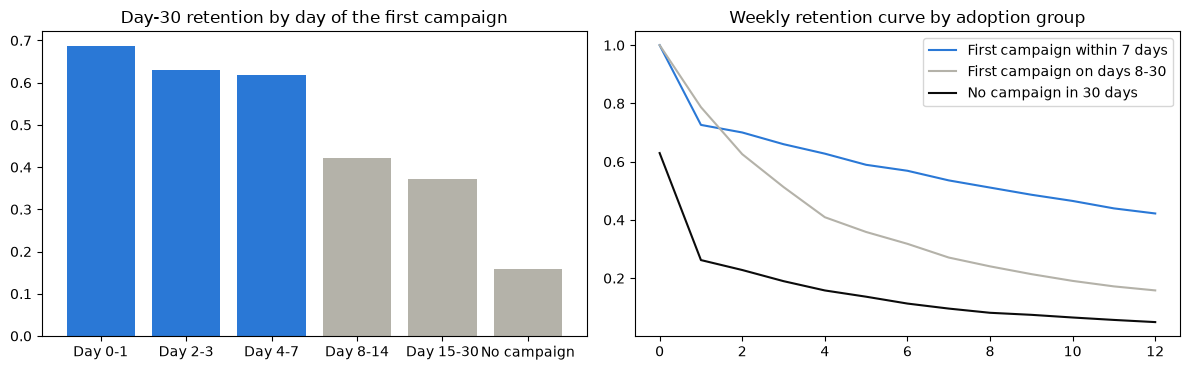

In [10]:
aha = pd.read_csv(OUT / "aha_retention.csv")
curve = pd.read_csv(OUT / "adoption_curve.csv")
print(aha[["first_campaign", "users", "share_of_users", "retention_d30", "upgrade_rate_60d"]].round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(aha.first_campaign, aha.retention_d30, color=[BLUE] * 3 + [GREY] * 3)
ax[0].set_title("Day-30 retention by day of the first campaign")
for g, c in zip(["First campaign within 7 days", "First campaign on days 8-30", "No campaign in 30 days"], [BLUE, GREY, INK]):
    d = curve[curve.adoption_group == g]
    ax[1].plot(d.week, d.retention, color=c, label=g)
ax[1].legend(); ax[1].set_title("Weekly retention curve by adoption group")
plt.tight_layout();

**Why 7 days?** Retention is flat for a first campaign on day 0-1, 2-3 or 4-7, then drops for days 8-14 and 15-30:
day 7 is where the curve breaks. Earlier thresholds (day 1) would miss most good users; later ones would mix in weaker ones.

**Correlation, not causation.** Users who send a campaign quickly are probably more motivated to begin with (a business with a
customer list ready). The gap persists inside every channel, platform and product (below), but stratifying only removes what we observe:
motivation itself is not in the data.

In [11]:
m30 = users[users.mature_d30 & users.funnel_complete].copy()
strata = []
for col, label in (("channel", "Acquisition channel"), ("platform", "Platform"), ("hosting_product", "Hosting product"), ("country", "Country")):
    g = m30.groupby([col, "activated_7d"]).retained_d30.mean().unstack()
    for value, row in g.iterrows():
        strata.append(dict(stratum_type=label, stratum=value, retention_aha=row[True], retention_no_aha=row[False],
                           gap=row[True] - row[False], users=(m30[col] == value).sum()))
strata = pd.DataFrame(strata)
strata = strata[strata.users >= 300]
strata.to_csv(OUT / "aha_strata.csv", index=False)
overall_gap = m30[m30.activated_7d].retained_d30.mean() - m30[~m30.activated_7d].retained_d30.mean()
print(f"overall gap: {overall_gap * 100:.0f} pts; gap inside strata: {strata.gap.min() * 100:.0f} to {strata.gap.max() * 100:.0f} pts")
strata.round(3).head(10)

overall gap: 44 pts; gap inside strata: 40 to 48 pts


,stratum_type,stratum,retention_aha,retention_no_aha,gap,users
0,Acquisition channel,Affiliates - Content,0.639,0.207,0.432,6380
1,Acquisition channel,Affiliates - Coupon,0.568,0.151,0.417,1446
2,Acquisition channel,Direct,0.614,0.189,0.425,4810
4,Acquisition channel,Influencers,0.652,0.209,0.443,3544
5,Acquisition channel,PPC Brand,0.658,0.180,0.478,4626
6,Acquisition channel,PPC Non-brand,0.619,0.179,0.440,9435
7,Acquisition channel,SEO,0.616,0.200,0.416,11689
8,Acquisition channel,Unattributed,0.651,0.205,0.446,895
9,Platform,Web - desktop,0.630,0.194,0.436,19431
10,Platform,Web - mobile,0.626,0.190,0.435,23401


**How to prove it: an encouragement test.** The A/B test above moved activation by about 2.5 points. If the full retention gap were
causal, retention should rise by about 2.5 × gap ≈ 1 point: far too small to see with 4,000 users per arm. To measure the causal
effect of the aha moment, randomise a much stronger push towards the first campaign (contacts-import assistant + day-2 reminder e-mail +
AI draft), and read retention by assigned group (intention to treat). Dividing the retention lift by the activation lift gives the causal
effect of activation (instrumental variable / Wald estimator).

In [12]:
def n_for_retention(p_base, lift, alpha=.05, power=.8):
    return n_per_arm(p_base, lift, alpha, power)

base_ret = m30.retained_d30.mean()
plan = []
for act_lift in (.025, .10, .15):
    for causal_share in (1.0, .33):
        ret_lift = act_lift * overall_gap * causal_share
        plan.append(dict(activation_lift=act_lift, causal_share_of_gap=causal_share, expected_retention_lift=ret_lift,
                         users_per_arm=n_for_retention(base_ret, ret_lift)))
enc = pd.DataFrame(plan)
enc.to_csv(OUT / "encouragement_test_plan.csv", index=False)
enc.round(4)

,activation_lift,causal_share_of_gap,expected_retention_lift,users_per_arm
0,0.025,1.00,0.0109,27933
1,0.025,0.33,0.0036,254763
2,0.100,1.00,0.0436,1794
3,0.100,0.33,0.0144,16082
4,0.150,1.00,0.0654,809
5,0.150,0.33,0.0216,7192


**Proposed definition of successful Reach adoption**

| Level | Metric | Why |
|---|---|---|
| Leading (week 1) | **Activation: first campaign within 7 days** | predicts retention, early enough to act on, moved by onboarding changes |
| Confirmation (week 5) | **Day-30 retention**: a core action in days 28-34 | proves the habit, not just a one-off campaign |
| Value (month 2) | **Upgrade to a paid plan within 60 days** | the business outcome (Reach Starter is limited to 100 recipients) |

Tracked by onboarding cohort, acquisition channel and platform, in completed windows only (censoring-safe).

## 3 · Hostinger Mail: do AI replies raise engagement, and for whom?

AI replies were rolled out in two waves: US, FR, ES on 1 June 2026, BR, IN, ID on 3 August 2026. Between those dates, wave 2 is a
natural control group. Difference-in-differences on each user's weekly average, pre (2 Mar - 31 May) vs post (1 Jun - 2 Aug), wave 1 vs wave 2.
This is an **intention-to-treat** effect: every mail user of wave 1 counts, whether they used the AI or not.

In [13]:
con = duckdb.connect()
uw = con.execute(f'''
    WITH e AS (
        SELECT user_id, event_name, CAST(event_time AS DATE) AS day,
               COALESCE(CAST(json_extract_string(event_properties, '$.count') AS INTEGER), 1) AS n
        FROM read_parquet('{(CLEAN / "sim_product_events.parquet").as_posix()}')
        WHERE product = 'Mail' AND event_time < TIMESTAMP '2026-08-03'
    )
    SELECT
        e.user_id, o.country, o.device, o.product AS hosting_product,
        CASE WHEN e.day < DATE '2026-06-01' THEN 'pre' ELSE 'post' END AS phase,
        COUNT(DISTINCT e.day) FILTER (WHERE e.event_name = 'mail_inbox_opened') AS active_days,
        SUM(e.n) FILTER (WHERE e.event_name = 'mail_message_sent') AS messages
    FROM e JOIN read_parquet('{(CLEAN / "sim_orders.parquet").as_posix()}') AS o USING (user_id)
    GROUP BY ALL
''').df()
WEEKS = {"pre": 13, "post": 9}
uw["active_days"] = uw.active_days.fillna(0) / uw.phase.map(WEEKS)
uw["messages"] = uw.messages.fillna(0) / uw.phase.map(WEEKS)
panel = uw.pivot_table(index=["user_id", "country", "device", "hosting_product"], columns="phase",
                       values=["active_days", "messages"], fill_value=0).reset_index()
panel.columns = ["_".join(c).strip("_") for c in panel.columns]
panel["wave"] = np.where(panel.country.isin(["US", "FR", "ES"]), 1, 2)
panel["segment"] = np.where(panel.device == "mobile", "Mobile",
                            np.where(panel.hosting_product.isin(["builder", "shared"]), "Desktop · website & hosting", "Desktop · cloud & VPS"))

def did_rel(df, y):
    # relative DiD: change in wave 1 minus change in wave 2, as a share of wave 1's pre-period level
    d = df[f"{y}_post"] - df[f"{y}_pre"]
    return (d[df.wave == 1].mean() - d[df.wave == 2].mean()) / df.loc[df.wave == 1, f"{y}_pre"].mean()

lift = []
for seg_name, df in [("All mail users", panel)] + list(panel.groupby("segment")):
    for y, label in (("messages", "Messages sent per week"), ("active_days", "Active days per week")):
        est = did_rel(df, y)
        w1, w2 = df[df.wave == 1], df[df.wave == 2]
        boots = [did_rel(pd.concat([w1.sample(len(w1), replace=True, random_state=int(rng.integers(10**9))),
                                    w2.sample(len(w2), replace=True, random_state=int(rng.integers(10**9)))]), y) for _ in range(500)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
        lift.append(dict(segment=seg_name, metric=label, users=len(df), did_lift=est, ci_low=lo, ci_high=hi))
mail_lift = pd.DataFrame(lift)
mail_lift.to_csv(OUT / "mail_ai_lift.csv", index=False)
mail_lift.round(3)

,segment,metric,users,did_lift,ci_low,ci_high
0,All mail users,Messages sent per week,10590,0.056,0.044,0.070
1,All mail users,Active days per week,10590,0.020,0.012,0.028
2,Desktop · cloud & VPS,Messages sent per week,699,0.021,-0.025,0.070
3,Desktop · cloud & VPS,Active days per week,699,-0.012,-0.041,0.019
4,Desktop · website & hosting,Messages sent per week,4091,0.007,-0.012,0.027
5,Desktop · website & hosting,Active days per week,4091,0.003,-0.009,0.016
6,Mobile,Messages sent per week,5800,0.095,0.079,0.113
7,Mobile,Active days per week,5800,0.036,0.026,0.047


**Reading.** The AI replies lift engagement for **mobile users** only (replying on a phone is where writing help saves the most time);
desktop users, and cloud / VPS customers in particular, do not change. The product decision is therefore not "AI for everyone" but
**put AI replies first in the mobile app** (one-tap suggested replies) and stop pushing them to desktop technical users.
Caution: the two waves are different countries; the pre-period trends are parallel (chart below), which supports the comparison.

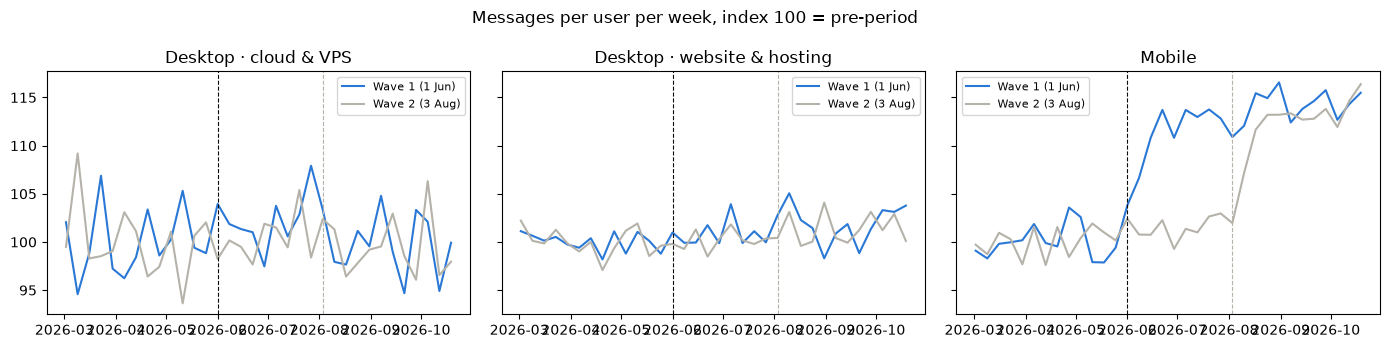

In [14]:
mw = pd.read_csv(OUT / "mail_weekly.csv", parse_dates=["week"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (s, d) in zip(axes, mw.groupby("segment")):
    for wv, c in (("Wave 1 (1 Jun)", BLUE), ("Wave 2 (3 Aug)", GREY)):
        x = d[d.rollout_wave == wv]
        ax.plot(x.week, x.messages_per_user / x.messages_per_user.iloc[:13].mean() * 100, color=c, label=wv)
    ax.axvline(pd.Timestamp("2026-06-01"), color=INK, ls="--", lw=.8); ax.axvline(pd.Timestamp("2026-08-03"), color=GREY, ls="--", lw=.8)
    ax.set_title(s); ax.legend(fontsize=8)
plt.suptitle("Messages per user per week, index 100 = pre-period"); plt.tight_layout();

## 4 · Referral programme: is the reward worth it?

Public terms: the referrer earns **20%** of the friend's purchase (up to 450 USD), the friend gets **20% off**, the reward is paid after
**45 days** (data/SOURCES.md). Cost per referral = reward (not paid if the friend refunds) + the friend's discount. A referral only creates
value if the friend would not have bought anyway, so the key number is the **break-even incrementality**: the share of referred friends
who must be truly new customers for the programme to pay back.

In [15]:
ref = pd.read_csv(OUT / "referral_detail.csv", parse_dates=["referral_date"])
band = pd.read_csv(OUT / "referral_by_band.csv")
rules = pd.read_csv(OUT / "referral_fraud_rules.csv")
flag = ref.flag_self_referral
cost_all = ref.programme_cost_eur.sum()
cost_flag = ref.loc[flag, "programme_cost_eur"].sum()
be_all = ref.programme_cost_eur.sum() / ref.loc[~flag, "expected_value_12m"].sum()
print(f"{len(ref):,} referrals; {flag.sum():,} flagged as self-referrals ({flag.mean():.1%}) costing €{cost_flag:,.0f} of €{cost_all:,.0f} ({cost_flag / cost_all:.0%})")
print(f"break-even incrementality, all bands: {be_all:.0%} of genuine referred friends must be new customers")
print(rules[["fraud_check", "referrals", "reward_eur", "median_minutes_link_to_signup", "median_minutes_signup_to_purchase"]].round(1).to_string(index=False))
band[["reward_band", "referrals", "flagged_self_referrals", "avg_plan_months", "programme_cost_eur", "value_12m_clean_eur", "break_even_incrementality"]].round(2)

3,620 referrals; 431 flagged as self-referrals (11.9%) costing €12,859 of €115,100 (11%)
break-even incrementality, all bands: 44% of genuine referred friends must be new customers
                         fraud_check  referrals  reward_eur  median_minutes_link_to_signup  median_minutes_signup_to_purchase
                               Clean       3092     42576.0                       205571.6                             1471.0
            Block: same payment card        356      4480.8                            2.0                               21.1
                 Review: same device         97      1473.1                       185932.2                             1993.6
Block: same device, sign-up < 10 min         75      1084.2                            1.8                               17.3


,reward_band,referrals,flagged_self_referrals,avg_plan_months,programme_cost_eur,value_12m_clean_eur,break_even_incrementality
0,< €5,494,71,6.46,2782.63,20325.30,0.14
1,€5-10,1181,143,33.53,19417.61,48494.53,0.40
2,€10-20,1339,149,35.50,43220.75,92950.44,0.46
3,€20-40,400,52,27.75,24150.40,50563.46,0.48
4,€40+,206,16,42.06,25529.02,50051.62,0.51


**Self-referrals.** A customer opens a second account, shares their own link and buys a few minutes later with the same card or on the same
device: they get 20% off **and** 20% back, for a purchase they were making anyway. The two "Block" rules catch that pattern (sign-up 2 minutes
after the link, purchase ~20 minutes later); "Review: same device" alone looks like households (sign-up days after the link) and should not be blocked.

**By reward level.** The biggest rewards come from long, expensive plans (48-month cloud plans): they pay the most upfront but also cost the most,
so they need the highest share of truly new customers to pay back. Small rewards are cheap insurance.

### 4.1 Scenario: what if the reward changes?

Assumptions (labelled, not measured: a real answer needs a reward test): genuine referrals respond to the reward with an elasticity of
0.5 or 1.0 (both shown); self-referrals respond faster (elasticity 1.5, more to gain); 50% of genuine referred friends are truly new
customers (sensitivity 30-70%);
with controls on, the two "Block" rules stop the reward and the discount at checkout.

In [16]:
months = (ref.referral_date.max() - ref.referral_date.min()).days / 30.4375
genuine, selfref = ref[~flag], ref[flag]
REWARD_CAP = 450 * .87

def scenario(rate, controls, incrementality=.5, elasticity=.5):
    g_scale = (rate / .20) ** elasticity
    s_scale = (rate / .20) ** 1.5
    def cost(df):
        reward = np.where(df.reward_status == "voided (refunded)", 0, np.minimum(rate * df.paid_amount_eur, REWARD_CAP))
        return reward.sum() + df.discount_cost_eur.sum()
    g_cost, s_cost = cost(genuine) * g_scale, (0 if controls else cost(selfref) * s_scale)
    value = genuine.expected_value_12m.sum() * g_scale * incrementality
    per_year = 12 / months
    return dict(reward_rate=rate, controls="Self-referral blocking" if controls else "No controls", incrementality=incrementality,
                elasticity=elasticity,
                genuine_referrals_year=len(genuine) * g_scale * per_year,
                self_referrals_year=0 if controls else len(selfref) * s_scale * per_year,
                cost_year_eur=(g_cost + s_cost) * per_year, incremental_value_year_eur=value * per_year,
                net_value_year_eur=(value - g_cost - s_cost) * per_year)

scen = pd.DataFrame([scenario(r, c, i, e) for r in (.10, .15, .20, .25, .30) for c in (False, True)
                     for i in (.3, .5, .7) for e in (.5, 1.0)])
scen.to_csv(OUT / "referral_scenarios.csv", index=False)
base = scen[scen.incrementality == .5].pivot_table(index="reward_rate", columns=["elasticity", "controls"], values="net_value_year_eur")
print("net value per year (EUR), 50% incrementality, by elasticity and controls:"); print(base.round(0))

net value per year (EUR), 50% incrementality, by elasticity and controls:
elasticity          0.5                                1.0                       
controls    No controls Self-referral blocking No controls Self-referral blocking
reward_rate                                                                      
0.10            22218.0                24654.0     14996.0                17433.0
0.15            18577.0                23672.0     15406.0                20500.0
0.20            11006.0                19801.0     11006.0                19801.0
0.25               95.0                13717.0      1714.0                15336.0
0.30           -13854.0                 5801.0    -12550.0                 7105.0


**Reading.** Blocking self-referrals is a **no-regret** move: it adds value at every reward level and matters more as the reward grows.
The reward level is not: if referrers respond weakly (elasticity 0.5), a lower reward earns more per year (fewer but cheaper referrals);
if they respond strongly (elasticity 1.0), the ranking changes. Historical data cannot tell which, because the rate never changed.
Next step: a reward test by referrer (10% vs 15% vs 20%) with a holdout region, to measure the elasticity and the incrementality instead of assuming them.

## 5 · Headline numbers used in the report

In [17]:
funnel = pd.read_csv(OUT / "reach_funnel.csv").set_index("step")
by_ch = pd.read_csv(OUT / "reach_adoption_by_channel.csv").set_index("channel")
aha_i = aha.set_index("first_campaign")
s20 = scen[(scen.incrementality == .5) & (scen.reward_rate == .20) & (scen.elasticity == .5)].set_index("controls")
mob = mail_lift[(mail_lift.segment == "Mobile") & (mail_lift.metric == "Messages sent per week")].iloc[0]
cloud = mail_lift[(mail_lift.segment == "Desktop · cloud & VPS") & (mail_lift.metric == "Messages sent per week")].iloc[0]
headline = {
    "funnel_starters": funnel.loc["Onboarding started", "users"],
    "funnel_template_rate": funnel.loc["Template chosen", "conversion_from_start"],
    "funnel_contacts_rate": funnel.loc["Contacts imported", "conversion_from_start"],
    "funnel_campaign_rate": funnel.loc["First campaign sent", "conversion_from_start"],
    "contacts_step_conversion": funnel.loc["Contacts imported", "conversion_from_previous"],
    "contacts_step_lost": funnel.loc["Contacts imported", "users_lost"],
    "activated_per_customer_influencers": by_ch.loc["Influencers", "activated_per_customer"],
    "activated_per_customer_ppc_nb": by_ch.loc["PPC Non-brand", "activated_per_customer"],
    "activated_per_customer_coupon": by_ch.loc["Affiliates - Coupon", "activated_per_customer"],
    "retention_d30_aha": m30[m30.activated_7d].retained_d30.mean(),
    "retention_d30_late": m30[m30.adoption_group == "First campaign on days 8-30"].retained_d30.mean(),
    "retention_d30_none": m30[m30.adoption_group == "No campaign in 30 days"].retained_d30.mean(),
    "aha_gap": overall_gap,
    "activated_7d_rate": m30.activated_7d.mean(),
    "ab_baseline": p0, "ab_mde": MDE, "ab_n_per_arm_plan": N_PLAN, "ab_n_available_per_arm": N_AVAILABLE,
    "ab_upgrade_diff": up["diff"], "ab_upgrade_p": up.p_value, "ab_upgrade_p_holm": up.p_holm,
    "ab_retention_diff": ret["diff"], "ab_interaction_p_min": inter.interaction_p.min(),
    "ab_srm_p": p_srm, "ab_srm_p_clean": p_srm_c, "ab_bug_day_users": int((ab.assigned_date == BUG_DAY).sum()),
    "ab_control": primary["control"], "ab_treatment": primary["treatment"], "ab_effect": primary["diff"],
    "ab_ci_low": primary["ci_low"], "ab_ci_high": primary["ci_high"], "ab_p_value": primary["p_value"],
    "ab_effect_with_bad_day": biased["diff"],
    "ab_n_clean": len(clean),
    "mail_mobile_lift": mob.did_lift, "mail_mobile_ci_low": mob.ci_low, "mail_mobile_ci_high": mob.ci_high,
    "mail_cloud_lift": cloud.did_lift,
    "referrals": len(ref), "self_referrals_flagged": int(flag.sum()), "self_referral_share": flag.mean(),
    "self_referral_cost_share": cost_flag / cost_all, "referral_cost_eur": cost_all,
    "referral_break_even_incrementality": be_all,
    "referral_net_no_controls": s20.loc["No controls", "net_value_year_eur"],
    "referral_net_controls": s20.loc["Self-referral blocking", "net_value_year_eur"],
}
pd.Series(headline, name="value").to_csv(OUT / "product_headline.csv")
pd.Series(headline).round(4)

funnel_starters                        43277.0000
funnel_template_rate                       0.8294
funnel_contacts_rate                       0.4744
funnel_campaign_rate                       0.3446
contacts_step_conversion                   0.5719
contacts_step_lost                     15366.0000
activated_per_customer_influencers         0.1652
activated_per_customer_ppc_nb              0.0739
activated_per_customer_coupon              0.0523
retention_d30_aha                          0.6276
retention_d30_late                         0.4093
retention_d30_none                         0.1579
aha_gap                                    0.4357
activated_7d_rate                          0.2424
ab_baseline                                0.2372
ab_mde                                     0.0270
ab_n_per_arm_plan                       4042.0000
ab_n_available_per_arm                  4074.0000
ab_upgrade_diff                           -0.0131
ab_upgrade_p                               0.0404
